In [51]:

# Import thư viện pandas
import pandas as pd

# Lấy tên file dữ liệu
file_path = "online_retail_II.xlsx"

# Đọc dữ liệu từ hai sheet
df1 = pd.read_excel(file_path, sheet_name="Year 2009-2010")
df2 = pd.read_excel(file_path, sheet_name="Year 2010-2011")

# Kiểm tra kích thước dữ liệu
print("Kích thước sheet Year 2009-2010:", df1.shape)
print("Kích thước sheet Year 2010-2011:", df2.shape)

# Hiển thị 5 dòng đầu tiên của sheet thứ nhất
display(df1.head())

# Hiển thị 5 dòng đầu tiên của sheet thứ hai
display(df2.head())


Kích thước sheet Year 2009-2010: (525461, 8)
Kích thước sheet Year 2010-2011: (541910, 8)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [52]:

# Kiểm tra thông tin dữ liệu của sheet thứ nhất
print("THÔNG TIN SHEET YEAR 2009-2010")
df1.info()

# Kiểm tra thông tin dữ liệu của sheet thứ hai
print("\nTHÔNG TIN SHEET YEAR 2010-2011")
df2.info()

# Kiểm tra thời gian bắt đầu và kết thúc của sheet thứ nhất
print("\nKHOẢNG THỜI GIAN SHEET 1")
print("Ngày bắt đầu:", df1["InvoiceDate"].min())
print("Ngày kết thúc:", df1["InvoiceDate"].max())

# Kiểm tra thời gian bắt đầu và kết thúc của sheet thứ hai
print("\nKHOẢNG THỜI GIAN SHEET 2")
print("Ngày bắt đầu:", df2["InvoiceDate"].min())
print("Ngày kết thúc:", df2["InvoiceDate"].max())


THÔNG TIN SHEET YEAR 2009-2010
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 525461 entries, 0 to 525460
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   Invoice      525461 non-null  object        
 1   StockCode    525461 non-null  object        
 2   Description  522533 non-null  object        
 3   Quantity     525461 non-null  int64         
 4   InvoiceDate  525461 non-null  datetime64[ns]
 5   Price        525461 non-null  float64       
 6   Customer ID  417534 non-null  float64       
 7   Country      525461 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 32.1+ MB

THÔNG TIN SHEET YEAR 2010-2011
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541910 entries, 0 to 541909
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   Invoice      541910 non-null  

In [53]:

# Xác định khoảng thời gian giao nhau
start_date = "2010-12-01"
end_date = "2010-12-09"

# Lọc dữ liệu thuộc khoảng thời gian giao nhau ở sheet thứ nhất
overlap_1 = df1[
    (df1["InvoiceDate"] >= start_date) &
    (df1["InvoiceDate"] < "2010-12-10")
]

# Lọc dữ liệu thuộc khoảng thời gian giao nhau ở sheet thứ hai
overlap_2 = df2[
    (df2["InvoiceDate"] >= start_date) &
    (df2["InvoiceDate"] < "2010-12-10")
]

# Kiểm tra số lượng bản ghi trong giai đoạn giao nhau
print("Số bản ghi giao nhau ở sheet 1:", len(overlap_1))
print("Số bản ghi giao nhau ở sheet 2:", len(overlap_2))

# Kiểm tra thời gian của dữ liệu giao nhau
print("Khoảng thời gian sheet 1:")
print(overlap_1["InvoiceDate"].min(), "đến", overlap_1["InvoiceDate"].max())

print("Khoảng thời gian sheet 2:")
print(overlap_2["InvoiceDate"].min(), "đến", overlap_2["InvoiceDate"].max())


Số bản ghi giao nhau ở sheet 1: 22523
Số bản ghi giao nhau ở sheet 2: 22523
Khoảng thời gian sheet 1:
2010-12-01 08:26:00 đến 2010-12-09 20:01:00
Khoảng thời gian sheet 2:
2010-12-01 08:26:00 đến 2010-12-09 20:01:00


In [54]:

# So sánh các thuộc tính giữa hai sheet
common_columns = df1.columns.tolist()

# Đếm số bản ghi khác nhau trong từng sheet ở giai đoạn giao nhau
unique_1 = overlap_1[common_columns].drop_duplicates()
unique_2 = overlap_2[common_columns].drop_duplicates()

# Tìm các bản ghi xuất hiện ở cả hai sheet
common_records = pd.merge(
    unique_1,
    unique_2,
    on=common_columns,
    how="inner"
)

# Kiểm tra kết quả so sánh
print("Số bản ghi khác nhau ở sheet 1:", len(unique_1))
print("Số bản ghi khác nhau ở sheet 2:", len(unique_2))
print("Số bản ghi trùng nhau giữa hai sheet:", len(common_records))


Số bản ghi khác nhau ở sheet 1: 22202
Số bản ghi khác nhau ở sheet 2: 22202
Số bản ghi trùng nhau giữa hai sheet: 22202


In [55]:

# Đếm số lần xuất hiện của từng bản ghi ở sheet thứ nhất
count_1 = overlap_1[common_columns].value_counts().reset_index(name="So_lan_sheet_1")

# Đếm số lần xuất hiện của từng bản ghi ở sheet thứ hai
count_2 = overlap_2[common_columns].value_counts().reset_index(name="So_lan_sheet_2")

# So sánh số lần xuất hiện giữa hai sheet
comparison = pd.merge(
    count_1,
    count_2,
    on=common_columns,
    how="outer"
)

# Thay thế giá trị thiếu bằng 0
comparison = comparison.fillna(0)

# Đếm số bản ghi có số lần xuất hiện khác nhau
different_counts = comparison[
    comparison["So_lan_sheet_1"] != comparison["So_lan_sheet_2"]
]

# Hiển thị kết quả
print("Số bản ghi có số lần xuất hiện khác nhau:", len(different_counts))


Số bản ghi có số lần xuất hiện khác nhau: 0


In [56]:

# Lọc dữ liệu sheet thứ hai từ ngày 10/12/2010 trở đi
df2_after = df2[df2["InvoiceDate"] >= "2010-12-10"]

# Ghép hai sheet thành một bộ dữ liệu
df = pd.concat([df1, df2_after], ignore_index=True)

# Kiểm tra kích thước dữ liệu sau khi ghép
print("Kích thước dữ liệu sau khi ghép:", df.shape)

# Kiểm tra thời gian của bộ dữ liệu sau khi ghép
print("Ngày bắt đầu:", df["InvoiceDate"].min())
print("Ngày kết thúc:", df["InvoiceDate"].max())

# Hiển thị 5 dòng đầu tiên
display(df.head())


Kích thước dữ liệu sau khi ghép: (1044848, 8)
Ngày bắt đầu: 2009-12-01 07:45:00
Ngày kết thúc: 2011-12-09 12:50:00


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [57]:

# Kiểm tra số lượng giá trị thiếu trong từng cột
print("SỐ LƯỢNG GIÁ TRỊ THIẾU")
print(df.isnull().sum())

# Kiểm tra tỷ lệ giá trị thiếu trong từng cột
print("\nTỶ LỆ GIÁ TRỊ THIẾU (%)")
print((df.isnull().sum() / len(df) * 100).round(2))

# Kiểm tra số lượng bản ghi trùng lặp hoàn toàn
print("\nSỐ BẢN GHI TRÙNG LẶP")
print("Số bản ghi trùng lặp:", df.duplicated().sum())


SỐ LƯỢNG GIÁ TRỊ THIẾU
Invoice             0
StockCode           0
Description      4275
Quantity            0
InvoiceDate         0
Price               0
Customer ID    235287
Country             0
dtype: int64

TỶ LỆ GIÁ TRỊ THIẾU (%)
Invoice         0.00
StockCode       0.00
Description     0.41
Quantity        0.00
InvoiceDate     0.00
Price           0.00
Customer ID    22.52
Country         0.00
dtype: float64

SỐ BẢN GHI TRÙNG LẶP
Số bản ghi trùng lặp: 11812


In [58]:

# Lọc các bản ghi trùng lặp hoàn toàn
duplicate_records = df[df.duplicated(keep=False)]

# Sắp xếp để các bản ghi giống nhau nằm gần nhau
duplicate_records = duplicate_records.sort_values(
    by=["Invoice", "StockCode", "InvoiceDate"]
)

# Hiển thị 20 dòng trùng lặp đầu tiên
display(duplicate_records.head(20))

# Kiểm tra số lượng hóa đơn có chứa bản ghi trùng lặp
print(
    "Số hóa đơn có chứa bản ghi trùng lặp:",
    duplicate_records["Invoice"].nunique()
)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
379,489517,21491,SET OF THREE VINTAGE GIFT WRAPS,1,2009-12-01 11:34:00,1.95,16329.0,United Kingdom
391,489517,21491,SET OF THREE VINTAGE GIFT WRAPS,1,2009-12-01 11:34:00,1.95,16329.0,United Kingdom
365,489517,21821,GLITTER STAR GARLAND WITH BELLS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
386,489517,21821,GLITTER STAR GARLAND WITH BELLS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
363,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
371,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
394,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
362,489517,21913,VINTAGE SEASIDE JIGSAW PUZZLES,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
385,489517,21913,VINTAGE SEASIDE JIGSAW PUZZLES,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
368,489517,22130,PARTY CONE CHRISTMAS DECORATION,6,2009-12-01 11:34:00,0.85,16329.0,United Kingdom


Số hóa đơn có chứa bản ghi trùng lặp: 4387


In [59]:

# Đếm số dòng trùng lặp trong từng hóa đơn
duplicate_by_invoice = duplicate_records.groupby("Invoice").size()

# Sắp xếp hóa đơn theo số dòng trùng lặp giảm dần
duplicate_by_invoice = duplicate_by_invoice.sort_values(
    ascending=False
)

# Hiển thị 10 hóa đơn có nhiều dòng trùng lặp nhất
print("10 hóa đơn có nhiều dòng trùng lặp nhất:")
display(duplicate_by_invoice.head(10))

# Kiểm tra số lượng hóa đơn có từ 2 dòng trùng lặp trở lên
print(
    "Số hóa đơn có ít nhất 2 dòng trùng lặp:",
    (duplicate_by_invoice >= 2).sum()
)


10 hóa đơn có nhiều dòng trùng lặp nhất:


,0
Invoice,
530437,58
547651,57
525075,56
579458,53
577482,52
572103,50
574481,49
552285,48
531922,48


Số hóa đơn có ít nhất 2 dòng trùng lặp: 4387


In [60]:

# Đếm số dòng trùng lặp cần loại bỏ nếu giữ lại một bản ghi
print(
    "Số dòng trùng lặp cần loại bỏ:",
    df.duplicated().sum()
)

# Tạo bộ dữ liệu thử nghiệm sau khi loại bỏ bản ghi trùng lặp
df_test = df.drop_duplicates()

# Kiểm tra kích thước dữ liệu sau khi loại bỏ
print("Kích thước dữ liệu ban đầu:", df.shape)
print("Kích thước dữ liệu sau khi loại bỏ:", df_test.shape)

# Kiểm tra số bản ghi trùng lặp còn lại
print("Số bản ghi trùng lặp còn lại:", df_test.duplicated().sum())


Số dòng trùng lặp cần loại bỏ: 11812
Kích thước dữ liệu ban đầu: (1044848, 8)
Kích thước dữ liệu sau khi loại bỏ: (1033036, 8)
Số bản ghi trùng lặp còn lại: 0


In [61]:

# Kiểm tra số lượng giá trị thiếu sau khi loại bỏ bản ghi trùng lặp
print("SỐ LƯỢNG GIÁ TRỊ THIẾU SAU KHI LOẠI BỎ TRÙNG LẶP")
print(df_test.isnull().sum())

# Kiểm tra tỷ lệ giá trị thiếu sau khi loại bỏ bản ghi trùng lặp
print("\nTỶ LỆ GIÁ TRỊ THIẾU (%)")
print((df_test.isnull().sum() / len(df_test) * 100).round(2))


SỐ LƯỢNG GIÁ TRỊ THIẾU SAU KHI LOẠI BỎ TRÙNG LẶP
Invoice             0
StockCode           0
Description      4275
Quantity            0
InvoiceDate         0
Price               0
Customer ID    235151
Country             0
dtype: int64

TỶ LỆ GIÁ TRỊ THIẾU (%)
Invoice         0.00
StockCode       0.00
Description     0.41
Quantity        0.00
InvoiceDate     0.00
Price           0.00
Customer ID    22.76
Country         0.00
dtype: float64


In [62]:

# Lọc các dòng bị thiếu Description
missing_description = df_test[df_test["Description"].isnull()]

# Lấy danh sách mã sản phẩm bị thiếu Description
missing_stock_codes = missing_description["StockCode"].unique()

# Kiểm tra số lượng mã sản phẩm bị thiếu Description
print(
    "Số lượng mã sản phẩm bị thiếu Description:",
    len(missing_stock_codes)
)

# Kiểm tra các mã sản phẩm này có Description trong dữ liệu hay không
description_check = df_test[
    df_test["StockCode"].isin(missing_stock_codes) &
    df_test["Description"].notnull()
]

print(
    "Số dòng có thể tìm thấy Description thông qua StockCode:",
    len(description_check)
)


Số lượng mã sản phẩm bị thiếu Description: 2451
Số dòng có thể tìm thấy Description thông qua StockCode: 366628


In [63]:

# Lọc các dòng có Description
valid_description = df_test[df_test["Description"].notnull()]

# Đếm số tên sản phẩm khác nhau theo từng mã StockCode
description_counts = valid_description.groupby("StockCode")["Description"].nunique()

# Lấy các mã sản phẩm có nhiều hơn một tên khác nhau
inconsistent_codes = description_counts[description_counts > 1]

# Kiểm tra kết quả
print(
    "Số mã StockCode có nhiều Description khác nhau:",
    len(inconsistent_codes)
)

# Hiển thị một số mã sản phẩm không nhất quán
print("\nMột số mã StockCode không nhất quán:")
display(inconsistent_codes.head(10))


Số mã StockCode có nhiều Description khác nhau: 1232

Một số mã StockCode không nhất quán:


,Description
StockCode,
10080,2
10120,2
10133,2
16008,2
16011,2
16012,2
16045,2
16235,2
17033,3


In [64]:

# Lấy các mã StockCode có duy nhất một Description
consistent_codes = description_counts[description_counts == 1].index

# Lọc các dòng thiếu Description thuộc những mã StockCode này
recoverable_rows = df_test[
    df_test["Description"].isnull() &
    df_test["StockCode"].isin(consistent_codes)
]

# Kiểm tra số lượng dòng có thể khôi phục
print(
    "Số dòng thiếu Description có thể khôi phục:",
    len(recoverable_rows)
)

# Kiểm tra số dòng thiếu Description chưa thể khôi phục
print(
    "Số dòng thiếu Description chưa thể khôi phục:",
    df_test["Description"].isnull().sum() - len(recoverable_rows)
)


Số dòng thiếu Description có thể khôi phục: 2974
Số dòng thiếu Description chưa thể khôi phục: 1301


In [65]:

# Tạo bảng ánh xạ giữa StockCode và Description
description_mapping = (
    valid_description[
        valid_description["StockCode"].isin(consistent_codes)
    ]
    .drop_duplicates(subset=["StockCode", "Description"])
    .set_index("StockCode")["Description"]
)

# Tạo bản dữ liệu mới để xử lý Description
df_clean = df_test.copy()

# Bổ sung Description từ StockCode
df_clean["Description"] = df_clean["Description"].fillna(
    df_clean["StockCode"].map(description_mapping)
)

# Kiểm tra số lượng Description còn thiếu
print(
    "Số lượng Description còn thiếu:",
    df_clean["Description"].isnull().sum()
)

# Kiểm tra kích thước dữ liệu sau xử lý
print("Kích thước dữ liệu:", df_clean.shape)


Số lượng Description còn thiếu: 1301
Kích thước dữ liệu: (1033036, 8)


In [66]:

# Lọc các dòng bị thiếu Customer ID
missing_customer = df_clean[df_clean["Customer ID"].isnull()]

# Thống kê số dòng thiếu Customer ID theo quốc gia
missing_by_country = missing_customer["Country"].value_counts()

# Hiển thị 15 quốc gia có nhiều dòng thiếu Customer ID nhất
print("SỐ DÒNG THIẾU CUSTOMER ID THEO QUỐC GIA")
display(missing_by_country.head(15))

# Kiểm tra tỷ lệ dòng thiếu Customer ID
print(
    "\nTỷ lệ dòng thiếu Customer ID:",
    round(len(missing_customer) / len(df_clean) * 100, 2),
    "%"
)


SỐ DÒNG THIẾU CUSTOMER ID THEO QUỐC GIA


,count
Country,
United Kingdom,232206
EIRE,1653
Hong Kong,360
Unspecified,231
France,128
Switzerland,117
United Arab Emirates,114
Portugal,114
Bahrain,67



Tỷ lệ dòng thiếu Customer ID: 22.76 %


In [67]:

# Tạo cột năm từ InvoiceDate
df_clean["Year"] = df_clean["InvoiceDate"].dt.year

# Thống kê tổng số giao dịch theo năm
total_by_year = df_clean.groupby("Year").size()

# Thống kê số giao dịch thiếu Customer ID theo năm
missing_by_year = (
    df_clean[df_clean["Customer ID"].isnull()]
    .groupby("Year")
    .size()
)

# Tổng hợp kết quả
year_comparison = pd.DataFrame({
    "Tổng số giao dịch": total_by_year,
    "Số giao dịch thiếu Customer ID": missing_by_year
})

# Tính tỷ lệ thiếu Customer ID theo năm
year_comparison["Tỷ lệ thiếu (%)"] = (
    year_comparison["Số giao dịch thiếu Customer ID"] /
    year_comparison["Tổng số giao dịch"] * 100
).round(2)

# Hiển thị kết quả
display(year_comparison)


,Tổng số giao dịch,Số giao dịch thiếu Customer ID,Tỷ lệ thiếu (%)
Year,,,
2009,44722,13446,30.07
2010,493653,102295,20.72
2011,494661,119410,24.14


In [68]:

# Kiểm tra số lượng Quantity âm, bằng 0 và dương
print("KIỂM TRA QUANTITY")
print("Quantity âm:", (df_clean["Quantity"] < 0).sum())
print("Quantity bằng 0:", (df_clean["Quantity"] == 0).sum())
print("Quantity dương:", (df_clean["Quantity"] > 0).sum())

# Kiểm tra số lượng Price âm, bằng 0 và dương
print("\nKIỂM TRA PRICE")
print("Price âm:", (df_clean["Price"] < 0).sum())
print("Price bằng 0:", (df_clean["Price"] == 0).sum())
print("Price dương:", (df_clean["Price"] > 0).sum())


KIỂM TRA QUANTITY
Quantity âm: 22496
Quantity bằng 0: 0
Quantity dương: 1010540

KIỂM TRA PRICE
Price âm: 5
Price bằng 0: 6014
Price dương: 1027017


In [69]:

# Chuyển Invoice sang kiểu chuỗi để kiểm tra ký tự đầu tiên
invoice_code = df_clean["Invoice"].astype(str)

# Lọc các giao dịch có Invoice bắt đầu bằng C
cancelled_transactions = df_clean[
    invoice_code.str.startswith("C")
]

# Thống kê số lượng giao dịch có Invoice bắt đầu bằng C
print(
    "Số giao dịch có Invoice bắt đầu bằng C:",
    len(cancelled_transactions)
)

# Kiểm tra số lượng âm trong các giao dịch này
print(
    "Số giao dịch có Quantity âm:",
    (cancelled_transactions["Quantity"] < 0).sum()
)

# Kiểm tra số lượng không âm trong các giao dịch này
print(
    "Số giao dịch có Quantity không âm:",
    (cancelled_transactions["Quantity"] >= 0).sum()
)


Số giao dịch có Invoice bắt đầu bằng C: 19104
Số giao dịch có Quantity âm: 19103
Số giao dịch có Quantity không âm: 1


In [70]:

# Lọc các giao dịch có Quantity âm
negative_quantity = df_clean[df_clean["Quantity"] < 0]

# Lọc các giao dịch có Quantity âm nhưng Invoice không bắt đầu bằng C
negative_not_cancelled = negative_quantity[
    ~negative_quantity["Invoice"].astype(str).str.startswith("C")
]

# Kiểm tra số lượng giao dịch
print(
    "Số giao dịch Quantity âm:",
    len(negative_quantity)
)

print(
    "Số giao dịch Quantity âm nhưng Invoice không bắt đầu bằng C:",
    len(negative_not_cancelled)
)

# Hiển thị 10 giao dịch đầu tiên
display(negative_not_cancelled.head(10))


Số giao dịch Quantity âm: 22496
Số giao dịch Quantity âm nhưng Invoice không bắt đầu bằng C: 3393


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Year
263,489464,21733,85123a mixed,-96,2009-12-01 10:52:00,0.0,NaN,United Kingdom,2009
283,489463,71477,short,-240,2009-12-01 10:52:00,0.0,NaN,United Kingdom,2009
284,489467,85123A,21733 mixed,-192,2009-12-01 10:53:00,0.0,NaN,United Kingdom,2009
470,489521,21646,NaN,-50,2009-12-01 11:44:00,0.0,NaN,United Kingdom,2009
3114,489655,20683,RAIN GIRL CHILDS UMBRELLA,-44,2009-12-01 17:26:00,0.0,NaN,United Kingdom,2009
3162,489660,35956,lost,-1043,2009-12-01 17:43:00,0.0,NaN,United Kingdom,2009
3168,489663,35605A,damages,-117,2009-12-01 18:02:00,0.0,NaN,United Kingdom,2009
4296,489806,18010,ASSORTED FRAGRANCE BATH CONFETTI,-770,2009-12-02 12:42:00,0.0,NaN,United Kingdom,2009
4538,489820,21133,invcd as 84879?,-720,2009-12-02 13:23:00,0.0,NaN,United Kingdom,2009
4566,489821,85049G,CHOCOLATE BOX RIBBONS,-240,2009-12-02 13:25:00,0.0,NaN,United Kingdom,2009


In [71]:

# Kiểm tra Price của các giao dịch Quantity âm không có Invoice bắt đầu bằng C
print("Số giao dịch có Price bằng 0:",
      (negative_not_cancelled["Price"] == 0).sum())

print("Số giao dịch có Price âm:",
      (negative_not_cancelled["Price"] < 0).sum())

print("Số giao dịch có Price dương:",
      (negative_not_cancelled["Price"] > 0).sum())

# Kiểm tra Customer ID bị thiếu trong nhóm giao dịch này
print(
    "Số giao dịch thiếu Customer ID:",
    negative_not_cancelled["Customer ID"].isnull().sum()
)

# Kiểm tra Description bị thiếu trong nhóm giao dịch này
print(
    "Số giao dịch thiếu Description:",
    negative_not_cancelled["Description"].isnull().sum()
)


Số giao dịch có Price bằng 0: 3393
Số giao dịch có Price âm: 0
Số giao dịch có Price dương: 0
Số giao dịch thiếu Customer ID: 3393
Số giao dịch thiếu Description: 746


In [72]:

# Lọc các giao dịch có Price âm
negative_price = df_clean[df_clean["Price"] < 0]

# Hiển thị toàn bộ giao dịch có Price âm
print("CÁC GIAO DỊCH CÓ PRICE ÂM")
display(negative_price)

# Kiểm tra StockCode của các giao dịch này
print("\nSTOCKCODE CỦA CÁC GIAO DỊCH PRICE ÂM")
print(negative_price["StockCode"].value_counts())

# Kiểm tra Description của các giao dịch này
print("\nDESCRIPTION CỦA CÁC GIAO DỊCH PRICE ÂM")
print(negative_price["Description"].value_counts())


CÁC GIAO DỊCH CÓ PRICE ÂM


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Year
179403,A506401,B,Adjust bad debt,1,2010-04-29 13:36:00,-53594.36,NaN,United Kingdom,2010
276274,A516228,B,Adjust bad debt,1,2010-07-19 11:24:00,-44031.79,NaN,United Kingdom,2010
403472,A528059,B,Adjust bad debt,1,2010-10-20 12:04:00,-38925.87,NaN,United Kingdom,2010
802921,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.06,NaN,United Kingdom,2011
802922,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.06,NaN,United Kingdom,2011



STOCKCODE CỦA CÁC GIAO DỊCH PRICE ÂM
StockCode
B    5
Name: count, dtype: int64

DESCRIPTION CỦA CÁC GIAO DỊCH PRICE ÂM
Description
Adjust bad debt    5
Name: count, dtype: int64


In [73]:

# Lọc các giao dịch có Price bằng 0
zero_price = df_clean[df_clean["Price"] == 0]

# Kiểm tra số lượng giao dịch theo Quantity
print("QUANTITY CỦA CÁC GIAO DỊCH PRICE BẰNG 0")
print("Quantity âm:", (zero_price["Quantity"] < 0).sum())
print("Quantity dương:", (zero_price["Quantity"] > 0).sum())

# Kiểm tra số lượng giao dịch theo Invoice
print("\nINVOICE CỦA CÁC GIAO DỊCH PRICE BẰNG 0")
print(
    "Invoice bắt đầu bằng C:",
    zero_price["Invoice"].astype(str).str.startswith("C").sum()
)

print(
    "Invoice không bắt đầu bằng C:",
    (~zero_price["Invoice"].astype(str).str.startswith("C")).sum()
)

# Kiểm tra một số mô tả phổ biến
print("\nDESCRIPTION PHỔ BIẾN")
display(zero_price["Description"].value_counts().head(15))


QUANTITY CỦA CÁC GIAO DỊCH PRICE BẰNG 0
Quantity âm: 3393
Quantity dương: 2621

INVOICE CỦA CÁC GIAO DỊCH PRICE BẰNG 0
Invoice bắt đầu bằng C: 0
Invoice không bắt đầu bằng C: 6014

DESCRIPTION PHỔ BIẾN


,count
Description,
check,160
?,91
damages,84
damaged,81
found,28
missing,27
sold as set on dotcom,20
CHILLI LIGHTS,17
Damaged,17


In [74]:

# Lọc giao dịch Price bằng 0 và Quantity dương
zero_price_positive = zero_price[
    zero_price["Quantity"] > 0
]

# Kiểm tra tình trạng thiếu Customer ID
print(
    "Số giao dịch thiếu Customer ID:",
    zero_price_positive["Customer ID"].isnull().sum()
)

# Kiểm tra tình trạng thiếu Description
print(
    "Số giao dịch thiếu Description:",
    zero_price_positive["Description"].isnull().sum()
)

# Thống kê các Description phổ biến
print("\nCÁC DESCRIPTION PHỔ BIẾN")
display(zero_price_positive["Description"].value_counts().head(20))

# Hiển thị một số giao dịch tiêu biểu
print("\nMỘT SỐ GIAO DỊCH PRICE BẰNG 0 VÀ QUANTITY DƯƠNG")
display(zero_price_positive.head(15))


Số giao dịch thiếu Customer ID: 2551
Số giao dịch thiếu Description: 555

CÁC DESCRIPTION PHỔ BIẾN


,count
Description,
check,39
found,28
CHILLI LIGHTS,15
adjustment,14
OWL DOORSTOP,14
POLYESTER FILLER PAD 45x45cm,12
POLYESTER FILLER PAD 40x40cm,10
MINT KITCHEN SCALES,9
FRENCH BLUE METAL DOOR SIGN 1,9



MỘT SỐ GIAO DỊCH PRICE BẰNG 0 VÀ QUANTITY DƯƠNG


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Year
3161,489659,21350,GINGHAM HEART WREATH,230,2009-12-01 17:39:00,0.0,NaN,United Kingdom,2009
3731,489781,84292,ROSE PINK METAL FOLDING CHAIR,17,2009-12-02 11:45:00,0.0,NaN,United Kingdom,2009
4674,489825,22076,6 RIBBONS EMPIRE,12,2009-12-02 13:34:00,0.0,16126.0,United Kingdom,2009
5904,489861,DOT,DOTCOM POSTAGE,1,2009-12-02 14:50:00,0.0,NaN,United Kingdom,2009
6378,489882,35751C,PURPLE CURRENT CANDLE RING,12,2009-12-02 16:22:00,0.0,NaN,United Kingdom,2009
6555,489898,79323G,NaN,954,2009-12-03 09:40:00,0.0,NaN,United Kingdom,2009
6581,489903,21166,NaN,48,2009-12-03 09:57:00,0.0,NaN,United Kingdom,2009
6781,489998,48185,DOOR MAT FAIRY CAKE,2,2009-12-03 11:19:00,0.0,15658.0,United Kingdom,2009
7204,490015,21982,PACK OF 12 SUKI TISSUES,467,2009-12-03 12:29:00,0.0,NaN,United Kingdom,2009
9249,490123,84508B,STRIPES DESIGN TEDDY,184,2009-12-03 18:08:00,0.0,NaN,United Kingdom,2009


In [75]:

# Thống kê số giao dịch Price bằng 0 theo StockCode
zero_price_by_stock = zero_price.groupby("StockCode").size()

# Sắp xếp theo số lượng giao dịch giảm dần
zero_price_by_stock = zero_price_by_stock.sort_values(
    ascending=False
)

# Hiển thị 15 StockCode có nhiều giao dịch Price bằng 0 nhất
print("15 STOCKCODE CÓ NHIỀU GIAO DỊCH PRICE BẰNG 0 NHẤT")
display(zero_price_by_stock.head(15))

# Kiểm tra số lượng StockCode khác nhau
print(
    "\nSố lượng StockCode có Price bằng 0:",
    zero_price["StockCode"].nunique()
)


15 STOCKCODE CÓ NHIỀU GIAO DỊCH PRICE BẰNG 0 NHẤT


,0
StockCode,
79321,17
22501,17
46000M,17
23084,16
22423,15
21116,15
46000S,14
20713,13
84990,13



Số lượng StockCode có Price bằng 0: 2971


In [76]:

# Lấy 15 StockCode có số giao dịch Price bằng 0 nhiều nhất
top_zero_stock = zero_price_by_stock.head(15).index

# Lọc các giao dịch thuộc 15 StockCode trên
top_zero_records = zero_price[
    zero_price["StockCode"].isin(top_zero_stock)
]

# Thống kê theo mã hàng, mô tả và số lượng
zero_stock_detail = (
    top_zero_records
    .groupby(["StockCode", "Description", "Quantity"], dropna=False)
    .size()
    .reset_index(name="Số lần xuất hiện")
)

# Sắp xếp theo số lần xuất hiện giảm dần
zero_stock_detail = zero_stock_detail.sort_values(
    by="Số lần xuất hiện",
    ascending=False
)

# Hiển thị kết quả
display(zero_stock_detail)


,StockCode,Description,Quantity,Số lần xuất hiện
115,79321,CHILLI LIGHTS,1,10
14,21116,OWL DOORSTOP,1,7
22,22139,NaN,1,5
15,21116,OWL DOORSTOP,2,4
136,84990,NaN,1,4
...,...,...,...,...
165,46000S,POLYESTER FILLER PAD 40x40cm,300,1
166,46000S,POLYESTER FILLER PAD 40x40cm,320,1
167,46000S,POLYESTER FILLER PAD 40x40cm,400,1
168,46000S,dotcom sales,-90,1


In [77]:

# Lọc các giao dịch có số lượng và đơn giá dương
positive_sales = df_clean[
    (df_clean["Quantity"] > 0) &
    (df_clean["Price"] > 0)
]

# Thống kê mô tả số lượng và đơn giá
print("THỐNG KÊ QUANTITY VÀ PRICE")
display(positive_sales[["Quantity", "Price"]].describe())

# Tính các ngưỡng phân vị để kiểm tra giá trị ngoại lệ
print("CÁC PHÂN VỊ QUANTITY")
display(positive_sales["Quantity"].quantile([0.25, 0.5, 0.75, 0.95, 0.99]))

print("CÁC PHÂN VỊ PRICE")
display(positive_sales["Price"].quantile([0.25, 0.5, 0.75, 0.95, 0.99]))


THỐNG KÊ QUANTITY VÀ PRICE


,Quantity,Price
count,1.007914e+06,1.007914e+06
mean,1.111717e+01,4.074618e+00
std,1.284700e+02,5.043177e+01
min,1.000000e+00,1.000000e-03
25%,1.000000e+00,1.250000e+00
50%,4.000000e+00,2.100000e+00
75%,1.200000e+01,4.130000e+00
max,8.099500e+04,2.511109e+04


CÁC PHÂN VỊ QUANTITY


,Quantity
0.25,1.0
0.50,4.0
0.75,12.0
0.95,31.0
0.99,108.0


CÁC PHÂN VỊ PRICE


,Price
0.25,1.25
0.50,2.10
0.75,4.13
0.95,9.95
0.99,18.00


In [78]:

# Tính các phân vị của Quantity
q1_quantity = positive_sales["Quantity"].quantile(0.25)
q3_quantity = positive_sales["Quantity"].quantile(0.75)

# Tính IQR và ngưỡng ngoại lệ của Quantity
iqr_quantity = q3_quantity - q1_quantity
upper_quantity = q3_quantity + 1.5 * iqr_quantity

# Tính các phân vị của Price
q1_price = positive_sales["Price"].quantile(0.25)
q3_price = positive_sales["Price"].quantile(0.75)

# Tính IQR và ngưỡng ngoại lệ của Price
iqr_price = q3_price - q1_price
upper_price = q3_price + 1.5 * iqr_price

# Hiển thị ngưỡng ngoại lệ
print("Ngưỡng ngoại lệ của Quantity:", upper_quantity)
print("Ngưỡng ngoại lệ của Price:", upper_price)

# Đếm số giao dịch vượt ngưỡng
print(
    "Số giao dịch Quantity vượt ngưỡng:",
    (positive_sales["Quantity"] > upper_quantity).sum()
)

print(
    "Số giao dịch Price vượt ngưỡng:",
    (positive_sales["Price"] > upper_price).sum()
)


Ngưỡng ngoại lệ của Quantity: 28.5
Ngưỡng ngoại lệ của Price: 8.45
Số giao dịch Quantity vượt ngưỡng: 53061
Số giao dịch Price vượt ngưỡng: 79000


In [79]:

# Sắp xếp giao dịch theo Quantity giảm dần
top_quantity = positive_sales.sort_values(
    by="Quantity",
    ascending=False
)

# Hiển thị 20 giao dịch có Quantity lớn nhất
display(
    top_quantity[
        ["Invoice", "StockCode", "Description", "Quantity",
         "InvoiceDate", "Price", "Country"]
    ].head(20)
)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Country
1043359,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2011-12-09 09:15:00,2.08,United Kingdom
564557,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,2011-01-18 10:01:00,1.04,United Kingdom
90857,497946,37410,BLACK AND WHITE PAISLEY FLOWER MUG,19152,2010-02-15 11:57:00,0.10,Denmark
127168,501534,21091,SET/6 WOODLAND PAPER PLATES,12960,2010-03-17 13:09:00,0.10,Denmark
127166,501534,21099,SET/6 STRAWBERRY PAPER CUPS,12960,2010-03-17 13:09:00,0.10,Denmark
127169,501534,21085,SET/6 WOODLAND PAPER CUPS,12744,2010-03-17 13:09:00,0.10,Denmark
127167,501534,21092,SET/6 STRAWBERRY PAPER PLATES,12480,2010-03-17 13:09:00,0.10,Denmark
135029,502269,21980,PACK OF 12 RED SPOTTY TISSUES,10000,2010-03-23 15:36:00,0.25,United Kingdom
135028,502269,21982,PACK OF 12 SUKI TISSUES,10000,2010-03-23 15:36:00,0.25,United Kingdom
135027,502269,21984,PACK OF 12 PINK PAISLEY TISSUES,10000,2010-03-23 15:36:00,0.25,United Kingdom


In [80]:

# Sắp xếp giao dịch theo Price giảm dần
top_price = positive_sales.sort_values(
    by="Price",
    ascending=False
)

# Hiển thị 20 giao dịch có Price cao nhất
display(
    top_price[
        ["Invoice", "StockCode", "Description", "Quantity",
         "InvoiceDate", "Price", "Country"]
    ].head(20)
)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Country
241827,512771,M,Manual,1,2010-06-17 16:53:00,25111.09,United Kingdom
517955,537632,AMAZONFEE,AMAZON FEE,1,2010-12-07 15:08:00,13541.33,United Kingdom
802920,A563185,B,Adjust bad debt,1,2011-08-12 14:50:00,11062.06,United Kingdom
135013,502263,M,Manual,1,2010-03-23 15:22:00,10953.50,United Kingdom
135015,502265,M,Manual,1,2010-03-23 15:28:00,10953.50,United Kingdom
372834,525399,M,Manual,1,2010-10-05 11:49:00,10468.80,United Kingdom
358639,524159,M,Manual,1,2010-09-27 16:12:00,10468.80,United Kingdom
342147,522796,M,Manual,1,2010-09-16 15:12:00,10468.80,United Kingdom
74356,496115,M,Manual,1,2010-01-29 11:04:00,8985.60,United Kingdom
676320,551697,POST,POSTAGE,1,2011-05-03 13:46:00,8142.75,United Kingdom


In [81]:

# Lọc các giao dịch có mã hàng hoặc mô tả đặc biệt
special_transactions = positive_sales[
    positive_sales["StockCode"].astype(str).isin(
        ["M", "AMAZONFEE", "POST", "DOT", "ADJUST", "B"]
    )
    |
    positive_sales["Description"].astype(str).str.contains(
        "manual|fee|postage|adjust|bad debt|dotcom",
        case=False,
        na=False
    )
]

# Kiểm tra số lượng giao dịch đặc biệt
print("Số giao dịch đặc biệt:", len(special_transactions))

# Thống kê theo mã hàng và mô tả
display(
    special_transactions.groupby(
        ["StockCode", "Description"],
        dropna=False
    ).size().sort_values(ascending=False).head(20)
)


Số giao dịch đặc biệt: 10602


,,0
StockCode,Description,
POST,POSTAGE,1851
DOT,DOTCOM POSTAGE,1415
M,Manual,847
22301,COFFEE MUG CAT + BIRD DESIGN,645
22303,COFFEE MUG APPLES DESIGN,541
22300,COFFEE MUG DOG + BALL DESIGN,530
21216,"SET 3 RETROSPOT TEA,COFFEE,SUGAR",503
37370,RETRO COFFEE MUGS ASSORTED,499
23243,SET OF TEA COFFEE SUGAR TINS PANTRY,471


In [82]:

# Lọc các giao dịch có mã hàng đặc biệt hoặc mô tả nghiệp vụ đặc biệt
special_transactions = positive_sales[
    positive_sales["StockCode"].astype(str).isin(
        ["M", "AMAZONFEE", "POST", "DOT", "ADJUST", "B"]
    )
    |
    positive_sales["Description"].astype(str).str.contains(
        r"\b(manual|fee|postage|adjust|bad debt|dotcom)\b",
        case=False,
        na=False,
        regex=True
    )
]

# Kiểm tra số lượng giao dịch đặc biệt
print("Số giao dịch đặc biệt:", len(special_transactions))

# Thống kê theo mã hàng và mô tả
display(
    special_transactions.groupby(
        ["StockCode", "Description"],
        dropna=False
    ).size().sort_values(ascending=False).head(20)
)


/tmp/ipykernel_4288/2900539869.py:7: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  positive_sales["Description"].astype(str).str.contains(


Số giao dịch đặc biệt: 4158


StockCode  Description                        
POST       POSTAGE                                1851
DOT        DOTCOM POSTAGE                         1415
M          Manual                                  847
ADJUST     Adjustment by john on 26/01/2010 16      20
           Adjustment by john on 26/01/2010 17      16
m          Manual                                    5
AMAZONFEE  AMAZON FEE                                3
B          Adjust bad debt                           1
dtype: int64

In [83]:

# Đếm số giao dịch hủy
cancelled_count = df_clean["Invoice"].astype(str).str.startswith("C").sum()

# Đếm số giao dịch có Quantity âm
negative_quantity_count = (df_clean["Quantity"] < 0).sum()

# Đếm số giao dịch có Price bằng 0
zero_price_count = (df_clean["Price"] == 0).sum()

# Đếm số giao dịch đặc biệt
special_count = len(special_transactions)

# Hiển thị kết quả thống kê
print("Số giao dịch hủy:", cancelled_count)
print("Số giao dịch có Quantity âm:", negative_quantity_count)
print("Số giao dịch có Price bằng 0:", zero_price_count)
print("Số giao dịch đặc biệt:", special_count)
print("Tổng số dòng dữ liệu hiện tại:", len(df_clean))


Số giao dịch hủy: 19104
Số giao dịch có Quantity âm: 22496
Số giao dịch có Price bằng 0: 6014
Số giao dịch đặc biệt: 4158
Tổng số dòng dữ liệu hiện tại: 1033036


In [84]:

# Xác định các giao dịch không phải giao dịch hủy
not_cancelled = ~df_clean["Invoice"].astype(str).str.startswith("C")

# Xác định các giao dịch có Quantity dương
positive_quantity = df_clean["Quantity"] > 0

# Xác định các giao dịch không thuộc nhóm nghiệp vụ đặc biệt
not_special = ~df_clean.index.isin(special_transactions.index)

# Tạo bộ dữ liệu bán hàng thông thường
df_sales = df_clean[
    not_cancelled &
    positive_quantity &
    not_special
].copy()

# Kiểm tra kích thước dữ liệu sau xử lý
print("Kích thước dữ liệu ban đầu:", df_clean.shape)
print("Kích thước dữ liệu bán hàng:", df_sales.shape)

# Kiểm tra các điều kiện sau làm sạch
print("Số Quantity âm còn lại:", (df_sales["Quantity"] < 0).sum())
print("Số giao dịch hủy còn lại:",
      df_sales["Invoice"].astype(str).str.startswith("C").sum())
print("Số giao dịch đặc biệt còn lại:",
      df_sales.index.isin(special_transactions.index).sum())


Kích thước dữ liệu ban đầu: (1033036, 9)
Kích thước dữ liệu bán hàng: (1006382, 9)
Số Quantity âm còn lại: 0
Số giao dịch hủy còn lại: 0
Số giao dịch đặc biệt còn lại: 0


In [85]:

# Kiểm tra giá trị thiếu trong bộ dữ liệu bán hàng
print("SỐ LƯỢNG GIÁ TRỊ THIẾU")
display(df_sales.isnull().sum())

# Kiểm tra tỷ lệ giá trị thiếu
print("\nTỶ LỆ GIÁ TRỊ THIẾU (%)")
display((df_sales.isnull().mean() * 100).round(2))

# Kiểm tra bản ghi trùng lặp
print("\nSố bản ghi trùng lặp:", df_sales.duplicated().sum())

# Kiểm tra số giao dịch có Price bằng 0
print("Số giao dịch Price bằng 0:", (df_sales["Price"] == 0).sum())

# Kiểm tra kích thước dữ liệu
print("Kích thước dữ liệu cuối bước lọc:", df_sales.shape)


SỐ LƯỢNG GIÁ TRỊ THIẾU


,0
Invoice,0
StockCode,0
Description,555
Quantity,0
InvoiceDate,0
Price,0
Customer ID,229419
Country,0
Year,0



TỶ LỆ GIÁ TRỊ THIẾU (%)


,0
Invoice,0.00
StockCode,0.00
Description,0.06
Quantity,0.00
InvoiceDate,0.00
Price,0.00
Customer ID,22.80
Country,0.00
Year,0.00



Số bản ghi trùng lặp: 0
Số giao dịch Price bằng 0: 2621
Kích thước dữ liệu cuối bước lọc: (1006382, 9)


In [86]:

# Kiểm tra kiểu dữ liệu của các cột
print("KIỂU DỮ LIỆU")
display(df_sales.dtypes)

# Tạo bản dữ liệu cuối cùng với các cột ban đầu
original_columns = [
    "Invoice", "StockCode", "Description", "Quantity",
    "InvoiceDate", "Price", "Customer ID", "Country"
]

df_final = df_sales[original_columns].copy()

# Kiểm tra kích thước dữ liệu cuối cùng
print("Kích thước dữ liệu cuối cùng:", df_final.shape)

# Kiểm tra lại tên các cột
print("Danh sách cột:")
print(df_final.columns.tolist())


KIỂU DỮ LIỆU


,0
Invoice,object
StockCode,object
Description,object
Quantity,int64
InvoiceDate,datetime64[ns]
Price,float64
Customer ID,float64
Country,object
Year,int32


Kích thước dữ liệu cuối cùng: (1006382, 8)
Danh sách cột:
['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country']


In [87]:

# Xuất bộ dữ liệu cuối cùng thành file Excel
output_file = "Online_Retail_II_Cleaned.xlsx"

df_final.to_excel(output_file, index=False)

# Thông báo hoàn thành
print("Đã xuất file:", output_file)
print("Số dòng:", len(df_final))
print("Số cột:", len(df_final.columns))


Đã xuất file: Online_Retail_II_Cleaned.xlsx
Số dòng: 1006382
Số cột: 8


In [88]:
# Đọc dữ liệu đã làm sạch
df_final = pd.read_excel("Online_Retail_II_Cleaned.xlsx")

# Chuyển InvoiceDate về kiểu ngày tháng
df_final["InvoiceDate"] = pd.to_datetime(df_final["InvoiceDate"])

# Tạo cột doanh thu
df_final["Revenue"] = df_final["Quantity"] * df_final["Price"]

# Kiểm tra dữ liệu
print("Số dòng dữ liệu:", len(df_final))
print("Số cột dữ liệu:", len(df_final.columns))

display(df_final.head())

Số dòng dữ liệu: 1006382
Số cột dữ liệu: 9


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Revenue
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,83.4
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,81.0
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,81.0
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,100.8
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,30.0


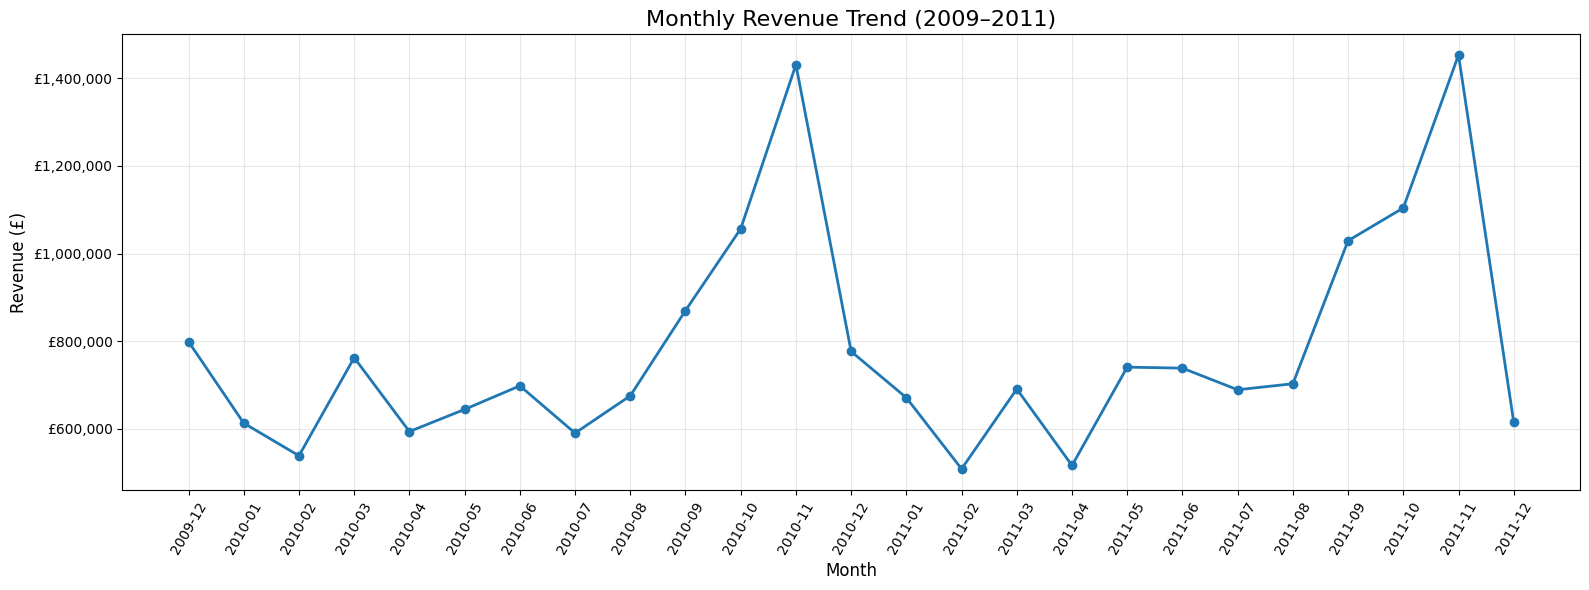

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [89]:
# 1. Import thư viện
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from google.colab import files

# 2. Tạo cột Revenue nếu chưa có
if "Revenue" not in df_final.columns:
    df_final["Revenue"] = df_final["Quantity"] * df_final["Price"]

# 3. Tính tổng doanh thu theo tháng
monthly_revenue = df_final.groupby(
    df_final["InvoiceDate"].dt.to_period("M")
)["Revenue"].sum()

# 4. Chuyển tháng thành dạng chữ để hiển thị
monthly_revenue.index = monthly_revenue.index.astype(str)

# 5. Vẽ biểu đồ
plt.figure(figsize=(16, 6))

plt.plot(
    monthly_revenue.index,
    monthly_revenue.values,
    marker="o",
    linewidth=2
)

plt.title("Monthly Revenue Trend (2009–2011)", fontsize=16)
plt.xlabel("Month", fontsize=12)
plt.ylabel("Revenue (£)", fontsize=12)

plt.xticks(rotation=60)
plt.grid(alpha=0.3)

# Định dạng doanh thu theo đơn vị tiền tệ
plt.gca().yaxis.set_major_formatter(
    ticker.StrMethodFormatter("£{x:,.0f}")
)

plt.tight_layout()

# 6. Lưu biểu đồ thành ảnh
plt.savefig(
    "/content/01_doanh_thu_theo_thang.png",
    dpi=300,
    bbox_inches="tight"
)

# 7. Hiển thị biểu đồ
plt.show()

# 8. Tải ảnh về máy
files.download("/content/01_doanh_thu_theo_thang.png")

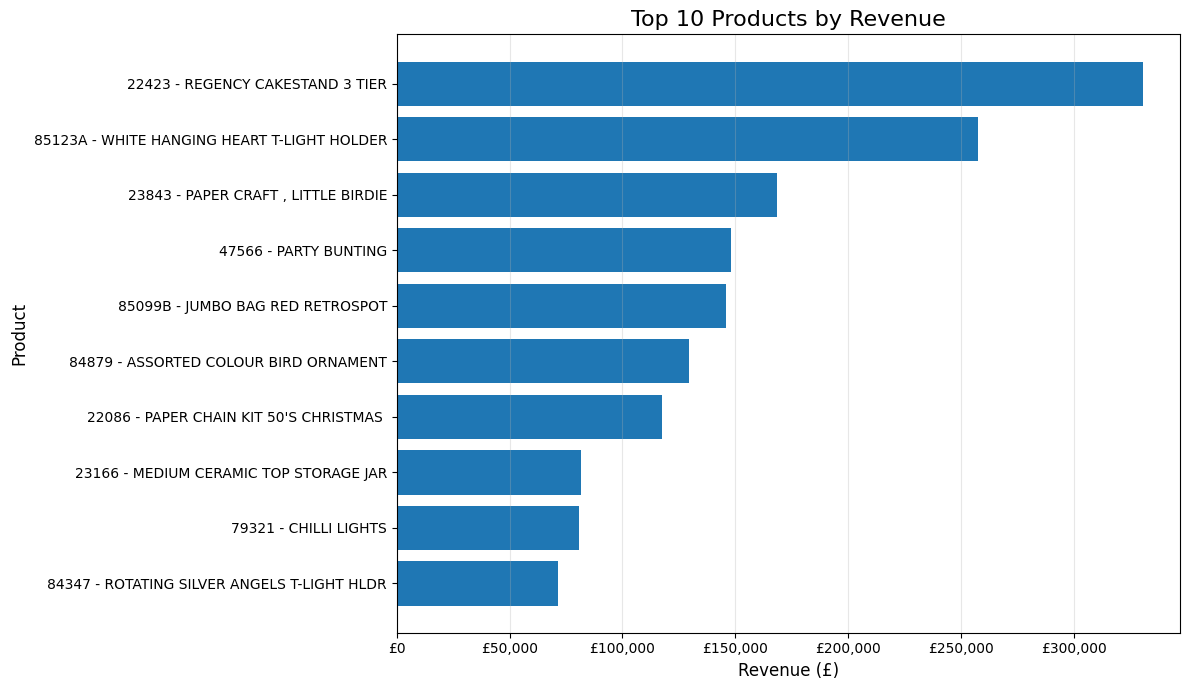

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [90]:
# 1. Import thư viện
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from google.colab import files

# 2. Tính tổng doanh thu của từng sản phẩm
top_products_revenue = (
    df_final.groupby(["StockCode", "Description"])["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .sort_values(ascending=True)
)

# 3. Tạo tên sản phẩm để hiển thị trên biểu đồ
product_names = [
    f"{stock_code} - {description}"
    for stock_code, description in top_products_revenue.index
]

# 4. Vẽ biểu đồ
plt.figure(figsize=(12, 7))

plt.barh(product_names, top_products_revenue.values)

plt.title("Top 10 Products by Revenue", fontsize=16)
plt.xlabel("Revenue (£)", fontsize=12)
plt.ylabel("Product", fontsize=12)

plt.gca().xaxis.set_major_formatter(
    ticker.StrMethodFormatter("£{x:,.0f}")
)

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()

# 5. Lưu biểu đồ
plt.savefig(
    "/content/02_top10_san_pham_doanh_thu.png",
    dpi=300,
    bbox_inches="tight"
)

# 6. Hiển thị biểu đồ
plt.show()

# 7. Tải ảnh về máy
files.download("/content/02_top10_san_pham_doanh_thu.png")

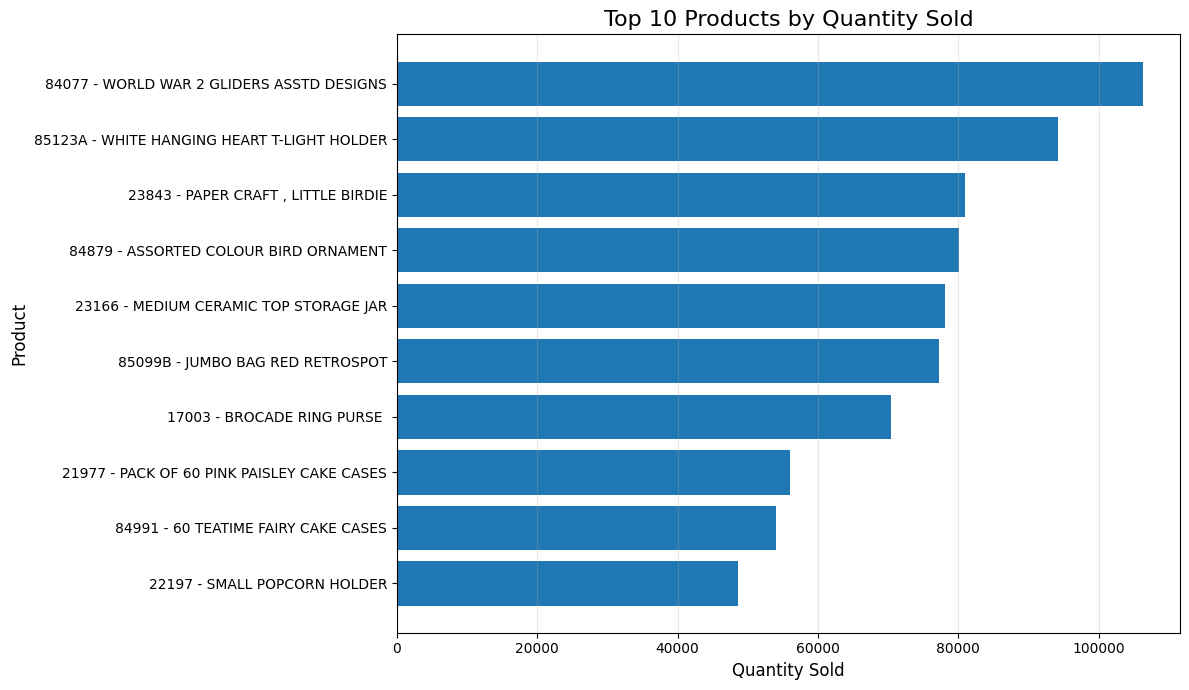

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [91]:
# 1. Import thư viện
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files

# 2. Tính tổng số lượng bán ra của từng sản phẩm
top_products_quantity = (
    df_final.groupby(["StockCode", "Description"])["Quantity"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .sort_values(ascending=True)
)

# 3. Tạo tên sản phẩm để hiển thị
product_names = [
    f"{stock_code} - {description}"
    for stock_code, description in top_products_quantity.index
]

# 4. Vẽ biểu đồ
plt.figure(figsize=(12, 7))

plt.barh(product_names, top_products_quantity.values)

plt.title("Top 10 Products by Quantity Sold", fontsize=16)
plt.xlabel("Quantity Sold", fontsize=12)
plt.ylabel("Product", fontsize=12)

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()

# 5. Lưu biểu đồ
plt.savefig(
    "/content/03_top10_san_pham_so_luong.png",
    dpi=300,
    bbox_inches="tight"
)

# 6. Hiển thị biểu đồ
plt.show()

# 7. Tải ảnh về máy
files.download("/content/03_top10_san_pham_so_luong.png")

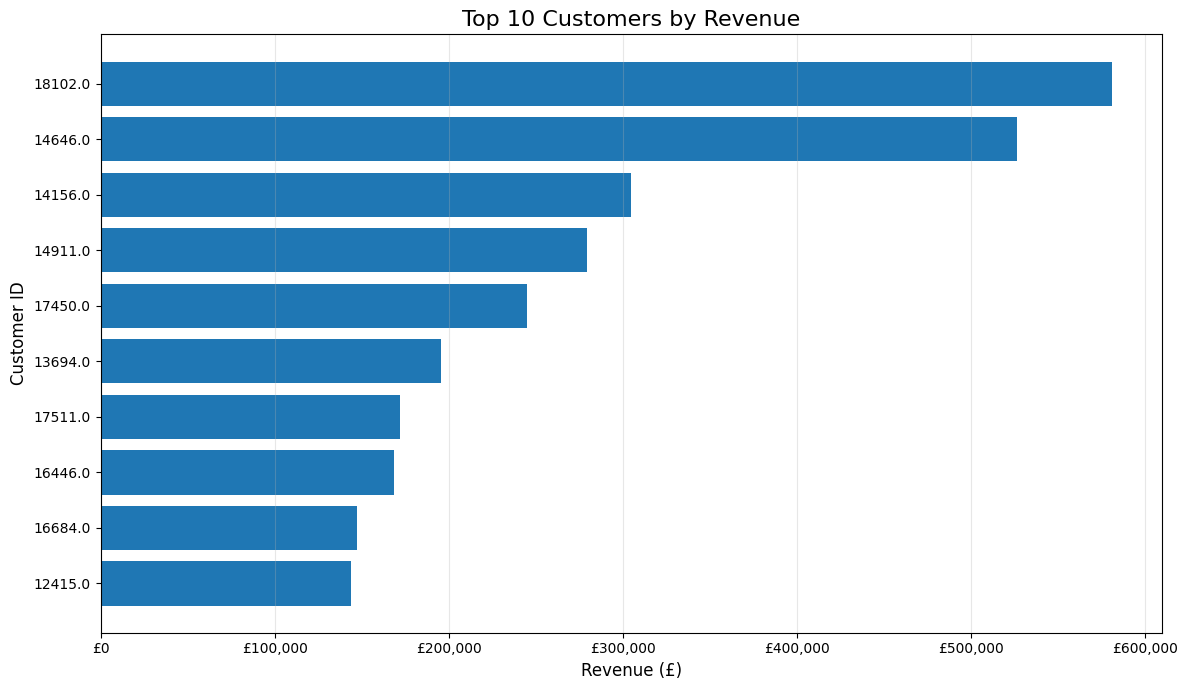

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [92]:
# 1. Import thư viện
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from google.colab import files

# 2. Loại bỏ các giao dịch không có mã khách hàng
customer_data = df_final.dropna(subset=["Customer ID"]).copy()

# 3. Tính tổng doanh thu của từng khách hàng
top_customers_revenue = (
    customer_data.groupby("Customer ID")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .sort_values(ascending=True)
)

# 4. Vẽ biểu đồ
plt.figure(figsize=(12, 7))

plt.barh(
    top_customers_revenue.index.astype(str),
    top_customers_revenue.values
)

plt.title("Top 10 Customers by Revenue", fontsize=16)
plt.xlabel("Revenue (£)", fontsize=12)
plt.ylabel("Customer ID", fontsize=12)

plt.gca().xaxis.set_major_formatter(
    ticker.StrMethodFormatter("£{x:,.0f}")
)

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()

# 5. Lưu biểu đồ
plt.savefig(
    "/content/04_top10_khach_hang_doanh_thu.png",
    dpi=300,
    bbox_inches="tight"
)

# 6. Hiển thị biểu đồ
plt.show()

# 7. Tải ảnh về máy
files.download("/content/04_top10_khach_hang_doanh_thu.png")

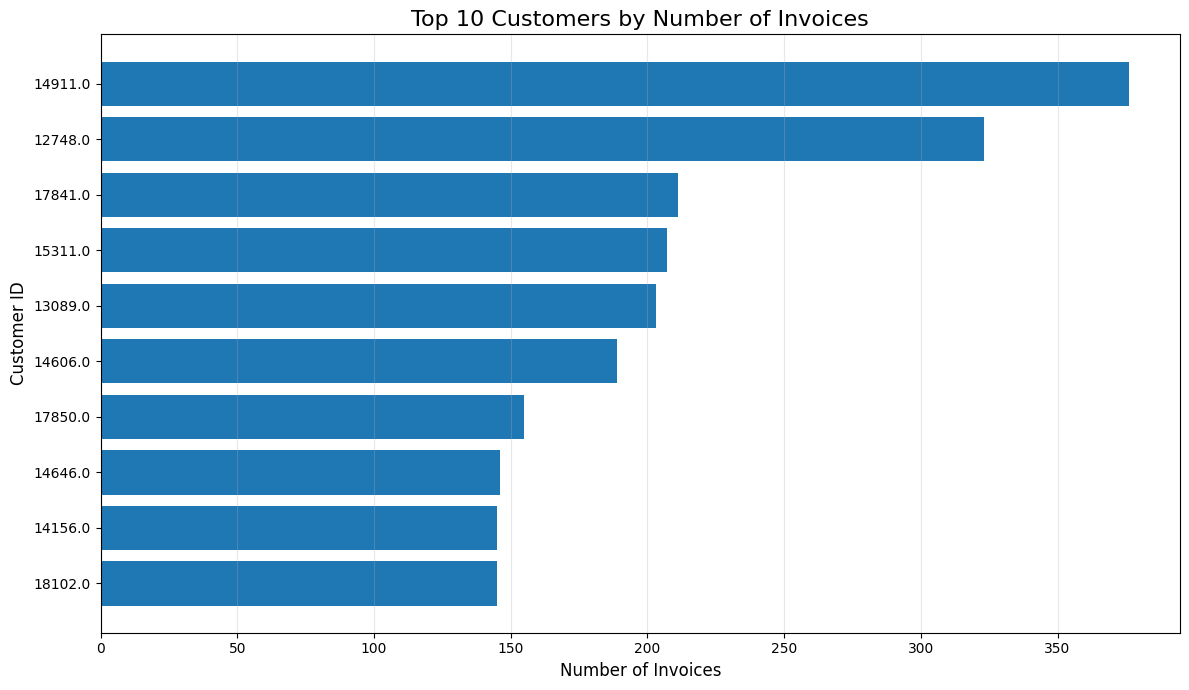

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [93]:
# 1. Import thư viện
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files

# 2. Lọc các giao dịch có mã khách hàng
customer_data = df_final.dropna(subset=["Customer ID"]).copy()

# 3. Đếm số hóa đơn khác nhau của từng khách hàng
top_customers_invoices = (
    customer_data.groupby("Customer ID")["Invoice"]
    .nunique()
    .sort_values(ascending=False)
    .head(10)
    .sort_values(ascending=True)
)

# 4. Vẽ biểu đồ
plt.figure(figsize=(12, 7))

plt.barh(
    top_customers_invoices.index.astype(str),
    top_customers_invoices.values
)

plt.title("Top 10 Customers by Number of Invoices", fontsize=16)
plt.xlabel("Number of Invoices", fontsize=12)
plt.ylabel("Customer ID", fontsize=12)

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()

# 5. Lưu biểu đồ
plt.savefig(
    "/content/05_top10_khach_hang_so_hoa_don.png",
    dpi=300,
    bbox_inches="tight"
)

# 6. Hiển thị biểu đồ
plt.show()

# 7. Tải ảnh về máy
files.download("/content/05_top10_khach_hang_so_hoa_don.png")

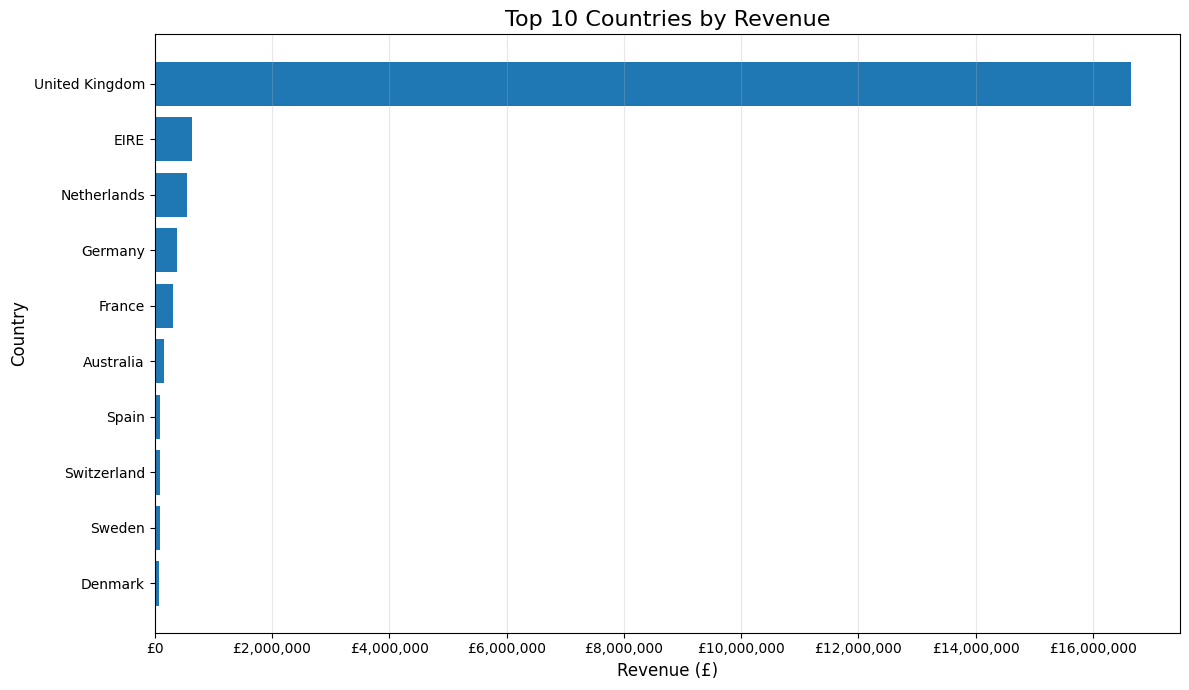

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [94]:
# 1. Import thư viện
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from google.colab import files

# 2. Tính tổng doanh thu theo từng quốc gia
top_countries_revenue = (
    df_final.groupby("Country")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .sort_values(ascending=True)
)

# 3. Vẽ biểu đồ
plt.figure(figsize=(12, 7))

plt.barh(
    top_countries_revenue.index,
    top_countries_revenue.values
)

plt.title("Top 10 Countries by Revenue", fontsize=16)
plt.xlabel("Revenue (£)", fontsize=12)
plt.ylabel("Country", fontsize=12)

plt.gca().xaxis.set_major_formatter(
    ticker.StrMethodFormatter("£{x:,.0f}")
)

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()

# 4. Lưu biểu đồ
plt.savefig(
    "/content/06_top10_quoc_gia_doanh_thu.png",
    dpi=300,
    bbox_inches="tight"
)

# 5. Hiển thị biểu đồ
plt.show()

# 6. Tải ảnh về máy
files.download("/content/06_top10_quoc_gia_doanh_thu.png")

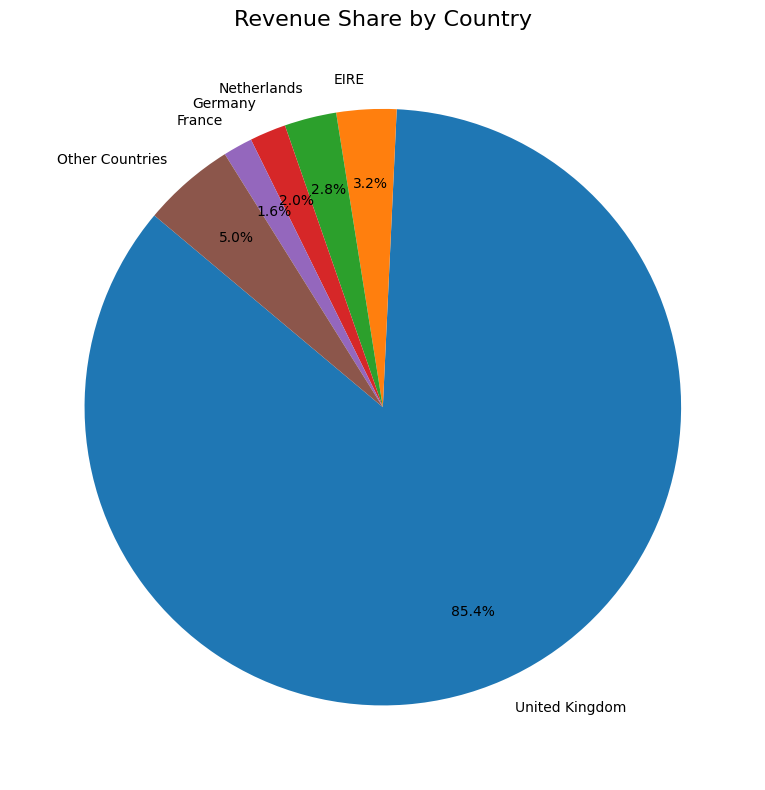

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [95]:
# 1. Import thư viện
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files

# 2. Tính tổng doanh thu theo quốc gia
country_revenue = (
    df_final.groupby("Country")["Revenue"]
    .sum()
    .sort_values(ascending=False)
)

# 3. Lấy Top 5 quốc gia
top_5_countries = country_revenue.head(5)

# 4. Gom các quốc gia còn lại thành Other Countries
other_countries = country_revenue.iloc[5:].sum()

revenue_share = pd.concat([
    top_5_countries,
    pd.Series({"Other Countries": other_countries})
])

# 5. Vẽ biểu đồ tròn
plt.figure(figsize=(10, 8))

plt.pie(
    revenue_share.values,
    labels=revenue_share.index,
    autopct="%1.1f%%",
    startangle=140,
    pctdistance=0.75
)

plt.title("Revenue Share by Country", fontsize=16)
plt.tight_layout()

# 6. Lưu biểu đồ
plt.savefig(
    "/content/07_ty_trong_doanh_thu_quoc_gia.png",
    dpi=300,
    bbox_inches="tight"
)

# 7. Hiển thị biểu đồ
plt.show()

# 8. Tải ảnh về máy
files.download("/content/07_ty_trong_doanh_thu_quoc_gia.png")